## AIR TRANSPORT
### Flight Delays

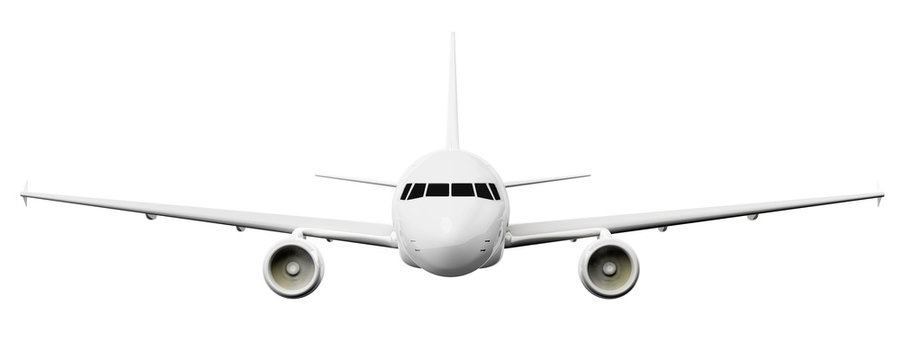

* Con este analisis se busca predecir retrasos a?reos superiores a 15 minutos. Esta predicci?n es crucial para la aerol?nea, ya que nos permitira conocer donde se pueden minimizar costos operativos (evitando acumulaci?n de retrasos).
Ademas se busca areas de mejora para la experiencia del cliente (menos molestias, mayor fidelidad).
Permitir planificaci?n anticipada, mejorando la eficiencia operativa.
Con los modelos a desarrollar (Random Forest, Logistic Regression y KNN), se pueden tomar decisiones estrat?gicas para prevenir o mitigar los retrasos, optimizar horarios, asignar recursos eficientemente y ofrecer soluciones proactivas a los pasajeros.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
data= pd.read_csv('Airline_Delay_Cause.csv')

In [ ]:
data

In [ ]:
data.tail()

In [ ]:
data.info()

data.describe()


In [ ]:
print(data.columns)

## DATA CLEANING

* Cuando los missing values son pocos, se pueden eliminar sin afectar el analisis.
* Usamos Dropna para eliminar los valores nulos.
* Convertimos las variables categoricas en numericas con LabelEncoder. 
* Verificamos duplicados y que ya no hayan missing values.

In [ ]:
data.isnull().sum()

In [ ]:
data_cleaned = data.dropna()

In [ ]:
from sklearn.preprocessing import LabelEncoder


le = LabelEncoder()

cat_cols = data_cleaned.select_dtypes(include=['object']).columns

for col in cat_cols:
       data_cleaned.loc[:, col] = le.fit_transform(data_cleaned[col])


In [ ]:
print(data_cleaned.info())

In [ ]:
data.duplicated().sum()

In [ ]:
data_cleaned.isnull().sum()

### Total delay distribution in minutes

Este grafico muestra la distribucion de los retrasos totales en minutos. 
Podemos obseevar en le grafico que la mayoria de los valores se concentran cerca de el valor 0 minutos, por lo que la mayioria
de los vuelos tienen retrasos bajos. 
Sin embargo, se logra observar un pequeno valor de vuelos con retrasos extremadamente largos de hasta 600,000 minutos, 
es decir mas de 400 dias, por lo que podria ser un error. 
dias= minutos / 60 x 24 
600,000/ 60x24 = 600,000/1,440 = 416.67 dias. 

Queremos realizar un mejor analisis, por lo que decidimos eliminar los valores atipicos.

Filtramos retrasos menores a 5000 minutos.

In [ ]:
dias = 600000 / (60*24)
print(dias)

In [ ]:
data["total_delay"] = data[["carrier_delay", "weather_delay", "nas_delay", "security_delay", "late_aircraft_delay"]].sum(axis=1)

plt.figure(figsize=(10, 6))
sns.histplot(data["total_delay"], bins=50, kde=True, color='blue')
plt.title("Total delay distribution in minutes")
plt.xlabel("Minutes Delay")
plt.show()

### Total distribution of delays in minutes (no outliers)

Filtramos los retrasos mayores a 5000 minutos.

In [ ]:
data_filtered = data[data["total_delay"] < 5000]  

plt.figure(figsize=(10, 6))
sns.histplot(data_filtered["total_delay"], bins=50, kde=True, color='blue')
plt.title("Total distribution of delays in minutes (no outliers)")
plt.xlabel("Minutes Delay")
plt.show()


#### Data pre-processing

* Vamos a definir la variable objetivo: 'arr_del15'. Esta variable indica si un vuelo tuvo un retraso mayor a 15 minutos (1 = s?, 0 = no).
* Se transform? la variable arr_del15 (retraso en minutos) en una variable categ?rica binaria (delay_15min), para convertir el problema en uno de clasificaci?n.
* 1: Vuelo con retraso mayor a 15 minutos.
  0: Vuelo puntual o con retraso igual o menor a 15 minutos.
* Esta transformaci?n responde al objetivo de negocio: identificar si un vuelo se retrasa o no, lo cual tiene implicaciones directas en planificaci?n y satisfacci?n del cliente.
  
* Posteriormente dividimos en datos de prueba y entrenamiento.
* 80% para entrenamiento
  20% para prueba
  
* Escalamos las variables. 

In [ ]:
data_cleaned = data.dropna().copy()

In [ ]:
data_cleaned.loc[:, 'delay_15min'] = data_cleaned['arr_del15'].apply(lambda x: 1 if x > 15 else 0)

In [ ]:
y = data_cleaned['delay_15min']
X = data_cleaned.drop(columns=['arr_del15', 'delay_15min'])

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# MODELS

### Random Forest

* Se utiliza Random Forest, ya que es un modelo robusto, basado en muchos ?rboles de decisi?n, que maneja bien datos con muchas variables (num?ricas y categ?ricas)
* Este modelo es ideal para predecir si un vuelo se retrasa bas?ndose en m?ltiples factores, como la aerol?nea, hora, clima, entre otros.
*  Podemos ver la cantidad de vuelos mayores a 15 minutos de retraso: 1    10713 y los vuelos sin retraso 0     9950.
* Se limita la cantidad y tamano de arboles para que se puedan analizar. Se usa 50 arboles en lugar de 100 y limita su profundida a 10 nivles. 
* Al ser muchos datos se pueden presentar problemas de datos de memoria en la maquina.

In [ ]:
print(y.value_counts())
print("N?mero de clases:", y.nunique())

In [ ]:
from sklearn.preprocessing import LabelEncoder

X_encoded = X.copy()

categorical_cols = X_encoded.select_dtypes(include=['object']).columns

le = LabelEncoder()
for col in categorical_cols:
    X_encoded[col] = le.fit_transform(X_encoded[col])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42)
model.fit(X_train, y_train)


In [ ]:
y_pred = model.predict(X_test)